# YOLO11s-seg (AutoFish): inferencia a varias resoluciones

Prueba `best.pt` sobre `Imagenes peces muestreo/` cambiando `imgsz`:

1. Grilla comparativa: **cada fila es una imagen**, **cada columna una resolución** (menor → mayor).
2. **Tiempo de inferencia promedio** por resolución.

> Esta carpeta **no tiene máscaras anotadas**, así que se usa `predict` y no `val`: no hay mAP, precisión ni recall.
> La comparación es visual (más detecciones o más confianza no implica necesariamente mejores máscaras).
> El modelo se entrenó con `imgsz=1024`.

## 1 · Configuración (editar acá)

In [1]:
# ── Rutas ────────────────────────────────────────────────────────────────────
WEIGHTS  = r"runs\yolo11s-seg_pescado_autofish-20261125T142058Z-1-001\yolo11s-seg_pescado_autofish\weights\best.pt"
IMG_DIR  = r"Imagenes peces muestreo/images"
METADATA = r"Imagenes peces muestreo/metadata.csv"   # opcional: agrega la especie al rótulo de la fila
OUT_DIR  = r"outputs/multires"

# ── Inferencia ───────────────────────────────────────────────────────────────
RESOLUCIONES = [640, 800, 960, 1024]  # múltiplos de 32; las columnas se ordenan solas de menor a mayor
DEVICE = None       # None = auto (GPU si hay), 0, o "cpu"
HALF   = False      # FP16 (solo GPU)

# ── Criterios para considerar una detección ──────────────────────────────────
CONF_MIN = 0.50     # confianza mínima: lo que esté por debajo se descarta
NMS_IOU  = 0.60     # IoU del NMS: si dos detecciones se solapan (IoU de cajas) más que esto, queda la de mayor confianza.
                    # Más bajo = elimina más duplicados. NO es IoU contra ground truth (no hay).
MAX_DET  = 50       # máximo de detecciones por imagen

# ── Colores de las máscaras (hex) ────────────────────────────────────────────
MODO_COLOR = "instancia"   # "instancia": un color por pez | "resolucion": un color por columna | "unico"
COLORES = ["#FF00FF", "#00FFFF", "#39FF14", "#FFFF00", "#FF6D00", "#FF1744", "#2979FF", "#D500F9"]
COLORES_RESOLUCION = {640: "#FF00FF", 800: "#00FFFF", 960: "#39FF14", 1024: "#FFFF00"}
COLOR_UNICO = "#39FF14"
ALPHA = 0.45               # opacidad del relleno (0 a 1)
GROSOR_CONTORNO = 2        # en píxeles de la miniatura
MOSTRAR_CONF = True        # escribir la confianza sobre cada máscara

# ── Grilla ───────────────────────────────────────────────────────────────────
N_IMAGENES       = None    # None = todas; un número = solo las primeras N (para probar rápido)
FILAS_POR_PAGINA = 20      # None = una sola figura gigante con todas las filas
ANCHO_CELDA_PX   = 400     # ancho de cada miniatura
DPI = 100

## 2 · Carga del modelo e imágenes

In [2]:
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from ultralytics import YOLO
from ultralytics.utils import ops

OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
RES = sorted(set(RESOLUCIONES))
assert all(r % 32 == 0 for r in RES), "Cada resolución tiene que ser múltiplo de 32"
assert MODO_COLOR in {"instancia", "resolucion", "unico"}, "MODO_COLOR inválido"
assert Path(WEIGHTS).exists(), f"No encuentro los pesos: {WEIGHTS}"

IMGS = sorted(p for p in Path(IMG_DIR).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})[:N_IMAGENES]
assert IMGS, f"No hay imágenes en {IMG_DIR}"

SPECIES = {}
if METADATA and Path(METADATA).exists():
    meta = pd.read_csv(METADATA)
    SPECIES = {Path(f).name: s for f, s in zip(meta.file_name, meta.species)}

model = YOLO(WEIGHTS)
dev = DEVICE if DEVICE is not None else (0 if torch.cuda.is_available() else "cpu")
dev_name = "CPU" if dev == "cpu" else torch.cuda.get_device_name(int(dev))
print(f"Clases: {model.names} | dispositivo: {dev_name} | {len(IMGS)} imágenes | resoluciones: {RES}")

Clases: {0: 'item'} | dispositivo: NVIDIA GeForce GTX 1650 | 110 imágenes | resoluciones: [640, 800, 960, 1024]


## 3 · Inferencia en todas las resoluciones

Se procesa de a una imagen (`batch=1`). Antes de medir cada resolución se hace un *warmup* con una foto de cada orientación,
para que la inicialización no ensucie los tiempos. La lectura de la foto desde disco **no** se cronometra.

In [3]:
def contornos(r):
    """Por instancia, lista de contornos (px de la imagen original). Se sacan del bitmap: `masks.xy`
    une las partes separadas de una máscara en un solo polígono y al dibujarlo aparecen líneas que la cruzan."""
    if r.masks is None: return []
    out = []
    for m in r.masks.data.cpu().numpy().astype(np.uint8):
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        out.append([ops.scale_coords(m.shape, c.reshape(-1, 2).astype(np.float32), r.orig_shape)
                    for c in cs if len(c) >= 3])
    return out

def inferir(img, imgsz):
    return model.predict(img, imgsz=imgsz, conf=CONF_MIN, iou=NMS_IOU, max_det=MAX_DET,
                         device=dev, half=HALF, verbose=False)[0]

# una foto horizontal y una vertical (si hay) para el warmup
muestras = {}
for p in IMGS:
    im = cv2.imread(str(p))
    muestras.setdefault(im.shape[0] > im.shape[1], im)
    if len(muestras) == 2: break

PRED, filas = {}, []
for imgsz in RES:
    for im in muestras.values():
        for _ in range(3): inferir(im, imgsz)
    for p in IMGS:
        r = inferir(cv2.imread(str(p)), imgsz)
        polys = contornos(r)
        confs = r.boxes.conf.cpu().numpy()
        PRED[p.name, imgsz] = (polys, confs)
        filas.append(dict(imagen=p.name, imgsz=imgsz, n_det=len(confs),
                          conf_max=float(confs.max()) if len(confs) else 0.0,
                          preproceso_ms=r.speed["preprocess"], inferencia_ms=r.speed["inference"],
                          postproceso_ms=r.speed["postprocess"]))
    print(f"imgsz={imgsz} listo")

df = pd.DataFrame(filas)
df.to_csv(OUT / "detecciones_por_imagen.csv", index=False)

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

## 4 · Grilla comparativa

Filas = imágenes, columnas = resoluciones (izquierda menor → derecha mayor). Cada celda indica cantidad de detecciones,
confianza máxima y tiempo de inferencia. Las páginas se guardan en `OUT_DIR`.

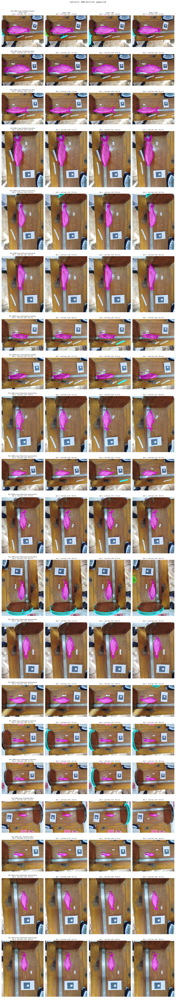

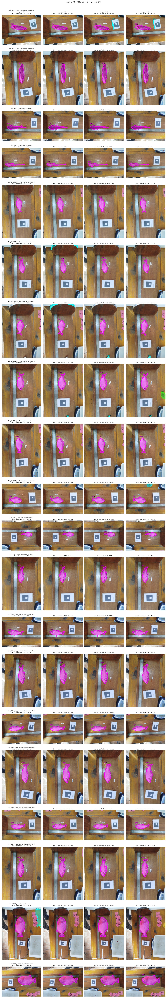

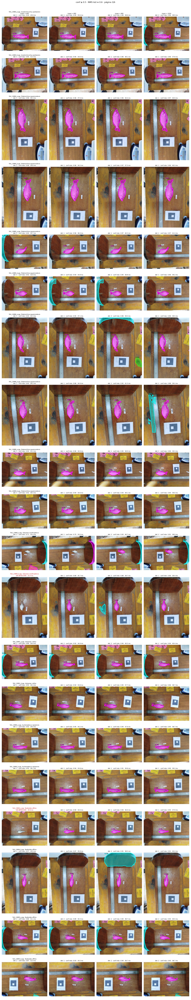

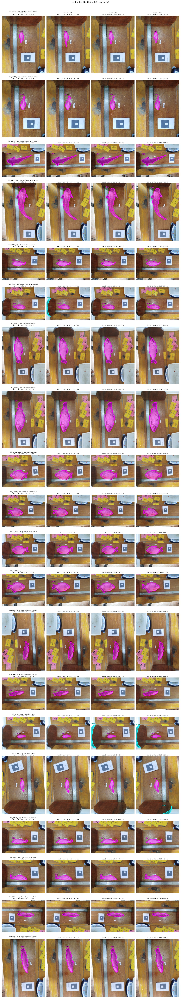

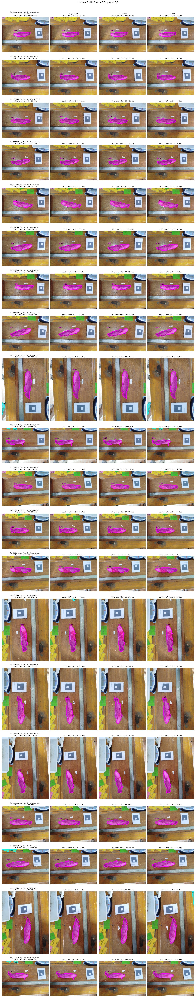

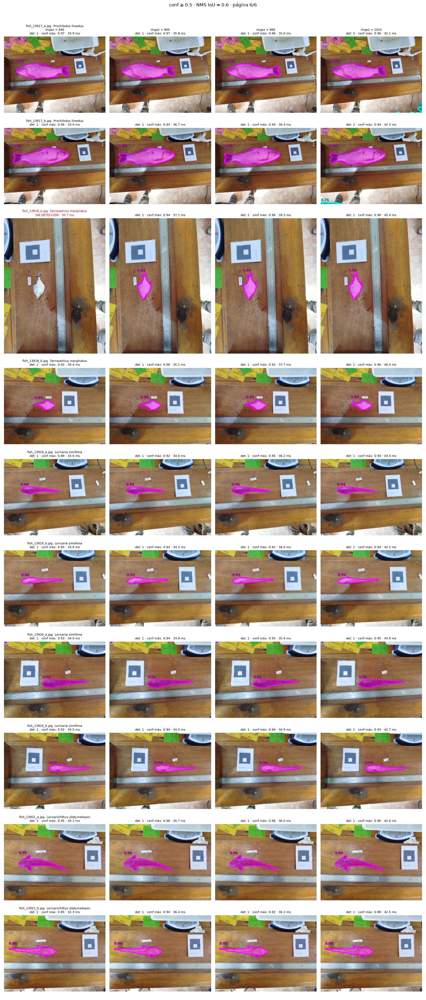

In [4]:
def hex2rgb(h):
    h = h.lstrip("#"); return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))

def color_para(i, imgsz):
    if MODO_COLOR == "unico": return hex2rgb(COLOR_UNICO)
    if MODO_COLOR == "resolucion":
        return hex2rgb(COLORES_RESOLUCION.get(imgsz, COLORES[RES.index(imgsz) % len(COLORES)]))
    return hex2rgb(COLORES[i % len(COLORES)])   # i = orden por confianza dentro de la imagen

def miniatura(path):
    im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    k = ANCHO_CELDA_PX / im.shape[1]
    return cv2.resize(im, None, fx=k, fy=k, interpolation=cv2.INTER_AREA), k

def pintar(base, k, polys, confs, imgsz):
    out = base.copy()
    items = [([np.round(q * k).astype(np.int32) for q in partes], c, color_para(i, imgsz))
             for i, (partes, c) in enumerate(zip(polys, confs)) if partes]
    for pts, _, col in items:
        capa = out.copy(); cv2.fillPoly(capa, pts, col)
        out = cv2.addWeighted(capa, ALPHA, out, 1 - ALPHA, 0)
    for pts, c, col in items:
        cv2.polylines(out, pts, True, col, GROSOR_CONTORNO, cv2.LINE_AA)
        if MOSTRAR_CONF:
            x, y = max(pts, key=len).min(axis=0)   # rótulo sobre la parte más grande
            pos = (max(int(x), 2), max(int(y) - 4, 14))
            cv2.putText(out, f"{c:.2f}", pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(out, f"{c:.2f}", pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1, cv2.LINE_AA)
    return out

INFO = df.set_index(["imagen", "imgsz"])

def pagina(paths, num, total):
    minis = [miniatura(p) for p in paths]
    altos = [m.shape[0] + 45 for m, _ in minis]          # +45 px para el título de cada celda
    w, h = ANCHO_CELDA_PX * len(RES) / DPI, (sum(altos) + 70) / DPI
    fig, ax = plt.subplots(len(paths), len(RES), figsize=(w, h), dpi=DPI, squeeze=False,
                           gridspec_kw={"height_ratios": altos})
    for i, (p, (base, k)) in enumerate(zip(paths, minis)):
        for j, imgsz in enumerate(RES):
            a = ax[i, j]; a.imshow(pintar(base, k, *PRED[p.name, imgsz], imgsz)); a.axis("off")
            s = INFO.loc[(p.name, imgsz)]
            det = f"det: {int(s.n_det)} · conf máx: {s.conf_max:.2f}" if s.n_det else "SIN DETECCIÓN"
            t = f"{det} · {s.inferencia_ms:.1f} ms"
            if i == 0: t = f"imgsz = {imgsz}\n{t}"
            if j == 0: t = f"{p.name}  {SPECIES.get(p.name, '')}\n{t}"
            a.set_title(t, fontsize=8, color="black" if s.n_det else "red")
    fig.suptitle(f"conf ≥ {CONF_MIN} · NMS IoU = {NMS_IOU} · página {num}/{total}", fontsize=12, y=1 - 10 / (h * DPI))
    fig.tight_layout(rect=(0, 0, 1, 1 - 40 / (h * DPI)))
    dest = OUT / f"grilla_{num:02d}.jpg"
    fig.savefig(dest, dpi=DPI, pil_kwargs={"quality": 85}); plt.close(fig)
    display(IPImage(filename=str(dest)))

for old in OUT.glob("grilla_*.jpg"): old.unlink()
paso = FILAS_POR_PAGINA or len(IMGS)
paginas = [IMGS[i:i + paso] for i in range(0, len(IMGS), paso)]
for n, pg in enumerate(paginas, 1):
    pagina(pg, n, len(paginas))

## 5 · Tiempo de inferencia promedio por resolución

`inferencia_ms` es solo el paso por la red. `total_ms` suma preproceso (redimensionado) y postproceso (NMS y máscaras).

Dispositivo: NVIDIA GeForce GTX 1650 | FP16: False | 110 imágenes, batch=1


,preproceso_ms,inferencia_ms,postproceso_ms,total_ms,inferencia_std_ms,inferencia_mediana_ms,FPS_total
imgsz,,,,,,,
640,2.65,31.38,3.20,37.23,5.68,32.88,26.86
800,3.56,33.70,2.61,39.87,3.28,34.47,25.08
960,4.75,38.50,2.91,46.16,2.15,38.55,21.67
1024,5.44,40.74,2.72,48.90,3.02,40.03,20.45


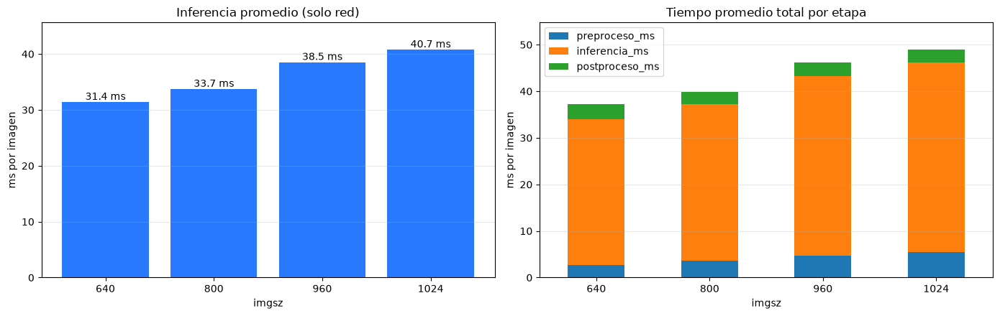

In [5]:
cols = ["preproceso_ms", "inferencia_ms", "postproceso_ms"]
tiempos = df.groupby("imgsz")[cols].mean()
tiempos["total_ms"] = tiempos[cols].sum(axis=1)
tiempos["inferencia_std_ms"] = df.groupby("imgsz").inferencia_ms.std()
tiempos["inferencia_mediana_ms"] = df.groupby("imgsz").inferencia_ms.median()
tiempos["FPS_total"] = 1000 / tiempos.total_ms
tiempos.to_csv(OUT / "tiempos_por_resolucion.csv")
print(f"Dispositivo: {dev_name} | FP16: {HALF} | {len(IMGS)} imágenes, batch=1")
display(tiempos.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = tiempos.index.astype(str)
barras = ax[0].bar(x, tiempos.inferencia_ms, color="#2979FF")
ax[0].bar_label(barras, fmt="%.1f ms"); ax[0].set_title("Inferencia promedio (solo red)")
tiempos[cols].set_axis(x).plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title("Tiempo promedio total por etapa")
for a in ax:
    a.set_xlabel("imgsz"); a.set_ylabel("ms por imagen"); a.margins(y=0.12); a.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "tiempos_por_resolucion.png", dpi=120); plt.show()